# Nafsi: Anxiety Prediction Models

**Senior Project, University of Sharjah**

This notebook shows the model development and testing steps of the Nafsi project:

1. **Input:** the supervisor's psychology dataset (2,000 participants)
2. **Preprocessing:** remove leakage columns, encode text columns, split 80% / 20%
3. **Model selection:** Decision Tree, Random Forest, Logistic Regression
4. **Evaluation:** accuracy, precision, recall, confusion matrix, feature importance
5. **Output:** comparison of the models, and why we moved to an LLM

> The 5 corrupted columns (Marital Status, Caffeine consumption, Smoking, Tags OCD, Bipolar Label) were already removed from the Excel file before this notebook, so the file has 22 columns instead of 27.

## 1. Setup and load the dataset
In Colab, run this cell and upload `psychology_data (senior).xlsx` when asked.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

FILE = 'psychology_data (senior).xlsx'

# Upload the file in Colab if it is not there yet
if not os.path.exists(FILE):
    from google.colab import files
    files.upload()

df = pd.read_excel(FILE)
df.columns = [c.strip() for c in df.columns]

print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))
print("Columns:", list(df.columns))

Number of rows: 2000
Number of columns: 22
Columns: ['ID', 'Age', 'Sex', 'Job', 'Education', 'Number of children', 'Sleep hours', 'Sleep Quality', 'Physical activity', 'Social interaction', 'Mood level', 'Stress level', 'Negative thoughts', 'Concentration problems', 'Feeling lonely', 'Family Support', 'Social Support', 'Depression Score (PHQ9)', 'Anxiety score (GAD7)', 'Two heartbeats', 'Depression Label', 'Anxiety Label']


In [2]:
# How many people have anxiety (1) and how many do not (0)
print(df['Anxiety Label'].value_counts())

Anxiety Label
1    1117
0     883
Name: count, dtype: int64


## 2. Preprocessing
- **Target:** `Anxiety Label` (1 = anxiety, 0 = no anxiety)
- **Leakage columns removed:** the GAD-7 and PHQ-9 scores and the Depression Label are almost the answer itself, so using them would be cheating. `ID` is removed because it has no meaning.
- **Encoding:** text columns are changed into numbers.
- **Split:** 80% for training and 20% for testing, keeping the same anxiety ratio in both.

In [3]:
target = 'Anxiety Label'
leakage_cols = ['Anxiety score (GAD7)', 'Depression Score (PHQ9)', 'Depression Label', 'ID']
feature_cols = [c for c in df.columns if c not in leakage_cols + [target]]

print("Features used for prediction:")
for c in feature_cols:
    print(" -", c)

X = df[feature_cols].copy()
y = df[target].copy()

# Encode text columns into numbers
for c in X.columns:
    if not pd.api.types.is_numeric_dtype(X[c]):
        X[c] = LabelEncoder().fit_transform(X[c].astype(str))

# Split into training data (80%) and testing data (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"\nTraining on {len(X_train)} people, testing on {len(X_test)} people")

Features used for prediction:
 - Age
 - Sex
 - Job
 - Education
 - Number of children
 - Sleep hours
 - Sleep Quality
 - Physical activity
 - Social interaction
 - Mood level
 - Stress level
 - Negative thoughts
 - Concentration problems
 - Feeling lonely
 - Family Support
 - Social Support
 - Two heartbeats

Training on 1600 people, testing on 400 people


## 3. Model selection and training
The same training and testing data is used for all three models, so the comparison is fair.

### 3.1 Decision Tree

In [4]:
dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

print(f"Accuracy:  {accuracy_score(y_test, dt_pred):.1%}")
print(f"Precision: {precision_score(y_test, dt_pred):.1%}")
print(f"Recall:    {recall_score(y_test, dt_pred):.1%}")

Accuracy:  59.2%
Precision: 58.3%
Recall:    94.6%


### 3.2 Random Forest
100 decision trees that vote together.

In [5]:
rf_model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print(f"Accuracy:  {accuracy_score(y_test, rf_pred):.1%}")
print(f"Precision: {precision_score(y_test, rf_pred):.1%}")
print(f"Recall:    {recall_score(y_test, rf_pred):.1%}")

Accuracy:  54.8%
Precision: 55.5%
Recall:    94.6%


### 3.3 Logistic Regression

In [6]:
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

print(f"Accuracy:  {accuracy_score(y_test, lr_pred):.1%}")

Accuracy:  53.5%


## 4. Evaluation
### 4.1 Comparison of the three models

In [7]:
results = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest', 'Logistic Regression'],
    'Accuracy': [accuracy_score(y_test, p) for p in (dt_pred, rf_pred, lr_pred)],
    'Precision': [precision_score(y_test, p) for p in (dt_pred, rf_pred)] + [None],
    'Recall': [recall_score(y_test, p) for p in (dt_pred, rf_pred)] + [None],
}).round(3)
results_table = results.fillna('-')
results_table

,Model,Accuracy,Precision,Recall
0,Decision Tree,0.592,0.583,0.946
1,Random Forest,0.548,0.555,0.946
2,Logistic Regression,0.535,-,-


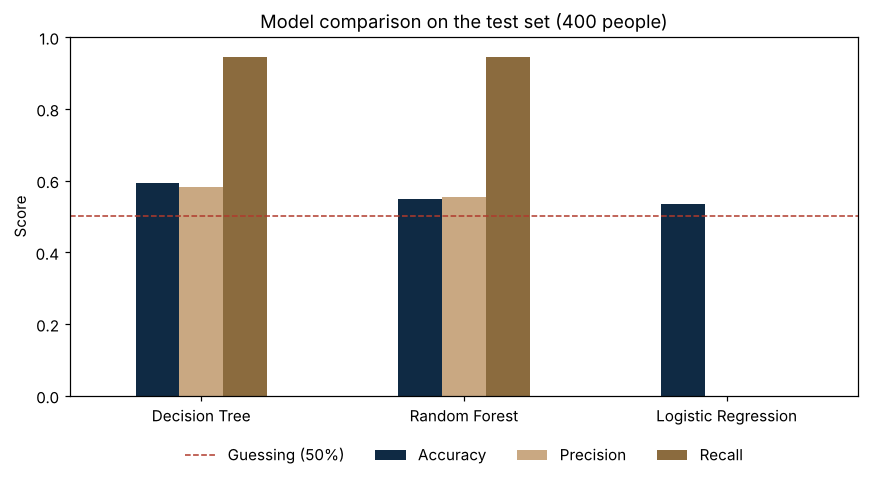

In [8]:
ax = results.set_index('Model')[['Accuracy', 'Precision', 'Recall']].plot(
    kind='bar', figsize=(8, 4.5), color=['#0F2A44', '#C9A882', '#8B6B3E'], rot=0)
ax.axhline(0.5, color='#B03A2C', linestyle='--', linewidth=1, label='Guessing (50%)')
ax.set_ylim(0, 1)
ax.set_ylabel('Score')
ax.set_title('Model comparison on the test set (400 people)')
ax.set_xlabel('')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=4, frameon=False)
plt.tight_layout()
plt.show()

### 4.2 Confusion matrix of the best model (Decision Tree)

In [9]:
cm = confusion_matrix(y_test, dt_pred)
print("                 Predicted: No   Predicted: Yes")
print(f"Actual: No       {cm[0][0]:>13}   {cm[0][1]:>14}")
print(f"Actual: Yes      {cm[1][0]:>13}   {cm[1][1]:>14}")
print(f"\n{cm[0][1]} people without anxiety were wrongly predicted as anxious.")

                 Predicted: No   Predicted: Yes
Actual: No                  26              151
Actual: Yes                 12              211

151 people without anxiety were wrongly predicted as anxious.


### 4.3 Most important features (Decision Tree)

Two heartbeats            0.165
Education                 0.162
Age                       0.135
Concentration problems    0.124
Sleep hours               0.106
dtype: float64


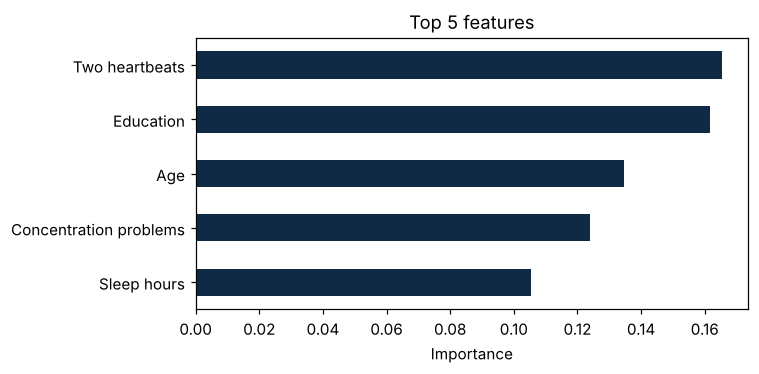

In [10]:
importances = pd.Series(dt_model.feature_importances_, index=feature_cols).sort_values(ascending=False)
print(importances.head(5).round(3))

ax = importances.head(5).sort_values().plot(kind='barh', figsize=(7, 3.5), color='#0F2A44')
ax.set_xlabel('Importance')
ax.set_title('Top 5 features')
plt.tight_layout()
plt.show()

## 5. Output and conclusion
- The best model was the **Decision Tree** with **59.2%** accuracy, which is only slightly better than guessing (50%).
- The recall is high (94.6%), but the precision is low (58.3%), so many people **without** anxiety were labeled as anxious.
- **Resting heart rate** ("Two heartbeats") was the most important feature, which supports using smartwatch data in the app.
- The models only give a Yes / No label, with no explanation, and cannot understand answers written by the user.

**Decision:** because of the low accuracy, we moved to an **LLM-based approach** (Google Gemini with prompt engineering), which is used in the Nafsi app.

## 6. LLM test (Google Gemini)
This section sends a few test participants to the Gemini API and compares its answer with the true label.

- Put your own API key in `API_KEY` (from aistudio.google.com/apikey). **Do not upload your key to GitHub.**
- The free plan has a daily request limit, so only a few people are tested.
- In our earlier test, 4 out of 7 successful requests matched the true label (about 57%), counted manually. Most other requests failed because of the free API limit.

In [ ]:
import time
import requests

API_KEY = "PUT_YOUR_KEY_HERE"
MODEL = "gemini-3.5-flash-lite"
URL = f"https://generativelanguage.googleapis.com/v1beta/models/{MODEL}:generateContent?key={API_KEY}"

def ask_gemini(person):
    details = "\n".join(f"{col}: {person[col]}" for col in feature_cols)
    prompt = ("Based on this person's data, predict if they have anxiety.\n"
              f"{details}\n\nAnswer with only the number 1 (anxiety) or 0 (no anxiety).")
    body = {"contents": [{"parts": [{"text": prompt}]}]}

    for attempt in range(4):              # retry if the service is busy
        r = requests.post(URL, json=body, timeout=40)
        if r.status_code == 200:
            text = r.json()['candidates'][0]['content']['parts'][0]['text'].strip()
            return 1 if text.startswith('1') else 0
        if r.status_code == 429:          # daily limit reached: stop
            print("Daily free limit reached.")
            return None
        time.sleep(6)                     # 503 busy: wait and try again
    return None

In [ ]:
N = 7
correct, answered = 0, 0

for i in range(N):
    person = df.loc[X_test.index[i]]
    actual = int(y_test.iloc[i])
    predicted = ask_gemini(person)
    if predicted is None:
        print(f"Person {i+1}: no answer")
        continue
    answered += 1
    correct += int(predicted == actual)
    print(f"Person {i+1}: Gemini = {predicted}, actual = {actual}")
    time.sleep(4)

if answered:
    print(f"\n{correct} out of {answered} answered correctly ({correct/answered:.0%})")